# Lab 12: Transformers

Guidelines: https://github.com/MohammedMosuily/Lab12

Run all cells using the environment in the repository README. This notebook explores the pretrained `bert-base-uncased` encoder; it does not fine-tune the model.

## Tasks 1 and 2: Transformer layers and attention heads

In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoTokenizer, AutoModel

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name, attn_implementation="eager")
model.eval()

number_of_layers = model.config.num_hidden_layers
heads_per_layer = model.config.num_attention_heads
print("Transformer layers:", number_of_layers)
print("Attention heads per layer:", heads_per_layer)
print("Total attention heads:", number_of_layers * heads_per_layer)

/Users/ali/Developer/nlp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformer layers: 12
Attention heads per layer: 12
Total attention heads: 144


## Task 3: Attention from the third layer and second head

Python uses zero-based indexing: layer 3 is index 2 and head 2 is index 1. Evaluation mode disables dropout, and eager attention returns the attention weights.

In [2]:
sentence = "Transformers use self-attention to understand language."
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Each layer has shape (batch, heads, query tokens, key tokens).
attention = outputs.attentions[2][0, 1].cpu()
print("Tokens:", tokens)
print("Layer 3, head 2 attention shape:", tuple(attention.shape))
assert len(outputs.attentions) == number_of_layers
assert attention.shape == (len(tokens), len(tokens))
assert torch.allclose(attention.sum(dim=-1), torch.ones(len(tokens)), atol=1e-5)
display(pd.DataFrame(attention.numpy(), index=tokens, columns=tokens).round(4))

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Layer 3, head 2 attention shape: (11, 11)


,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.7318,0.0079,0.0106,0.0056,0.0165,0.0069,0.0101,0.0116,0.0055,0.0386,0.1550
transformers,0.8888,0.0047,0.0344,0.0002,0.0027,0.0051,0.0009,0.0007,0.0004,0.0051,0.0570
use,0.1427,0.5689,0.0054,0.0353,0.0412,0.0679,0.0896,0.0003,0.0053,0.0090,0.0343
self,0.3395,0.0732,0.0015,0.0002,0.2016,0.0811,0.0636,0.0257,0.0016,0.0285,0.1835
-,0.1429,0.0697,0.0713,0.6394,0.0121,0.0128,0.0034,0.0026,0.0142,0.0093,0.0223
attention,0.1126,0.5448,0.0116,0.0203,0.1112,0.0102,0.0724,0.0001,0.0001,0.0164,0.1003
to,0.0841,0.0224,0.6222,0.0085,0.0091,0.1936,0.0110,0.0072,0.0008,0.0140,0.0271
understand,0.4336,0.0050,0.0023,0.0216,0.0119,0.0030,0.3296,0.0024,0.0554,0.0533,0.0820
language,0.0513,0.0005,0.4292,0.0016,0.0045,0.0013,0.0051,0.3980,0.0059,0.0407,0.0620
.,0.6580,0.0056,0.0031,0.0011,0.0044,0.0025,0.0094,0.0379,0.0459,0.0726,0.1594


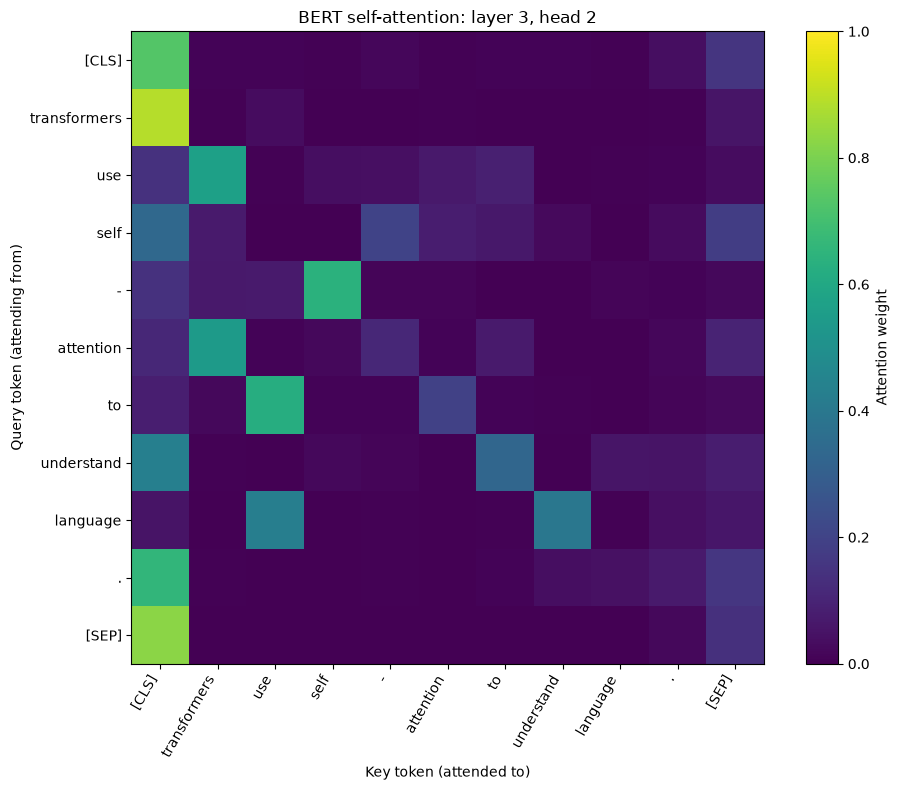

In [3]:
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(attention.numpy(), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(tokens)), tokens, rotation=60, ha="right")
ax.set_yticks(range(len(tokens)), tokens)
ax.set_xlabel("Key token (attended to)")
ax.set_ylabel("Query token (attending from)")
ax.set_title("BERT self-attention: layer 3, head 2")
fig.colorbar(image, ax=ax, label="Attention weight")
fig.tight_layout()
plt.show()

## Task 4: Meaning of the rows and columns

Each **row** represents a query token: the token whose representation is being updated. Each **column** represents a key token: a token that the query can attend to. Entry `(i, j)` is the attention weight assigned by token `i` to token `j` in this particular layer and head.

Tokens include `[CLS]`, `[SEP]`, punctuation, and any WordPiece fragments produced by BERT's tokenizer. This is an encoder, so tokens can attend to both earlier and later tokens, as well as themselves. Each row sums to approximately 1 because attention uses softmax over the keys. A larger weight means a greater contribution within this head; it is not a direct measure of a word's overall importance to a prediction.